# Prva Zadaća
Podaci i problem koji ćemo analizirati pronađeni su na stranici Geeks for Geeks ([Dataset for Linear Regression](https://www.geeksforgeeks.org/dataset-for-linear-regression/)).


### Advertising Dataset

Ovaj skup podataka sadrži informacije o količini prodanih proizvoda u odnosu na proračune za oglašavanje na TV-u, radiju i u novinama. Obično se koristi za istraživanje odnosa između marketinških napora i prodaje.

- Izvor Skupa Podataka: Advertising Dataset
- Oznake: Kontinuirane vrijednosti koje predstavljaju novac potrošen na oglašavanje i broj prodanih proizvoda (u tisućama)
- Veličina: 200 uzoraka, svaki s 4 atributa
- Vrsta Podataka: Numerički podaci


Glavni cilj je istražiti ovisi li prodaja proučavanog proizvoda o novcu uloženom u oglašavnje.

#### *Učitavanje i Pročišćavanje Skupa Podataka*

In [1]:
import pandas as pd # ucitavanje librarya pandas
import numpy as np # ucitavanje librarya numpy

df = pd.read_csv('advertising.csv') # ucitavanje podataka u dataframe iz csv dokumenta
df.head() # provjeravamo je li tablica dobro ucitana

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


Provjeravamo jesu li podaci u tablici ispravno unešeni

In [13]:
df.info() # informacije o data frameu

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [ ]:
df.duplicated().sum() # broj dupliciranih vrijednosti

0

DataFrame `df` je pripremljen za analizu budući da ne sadrži NaN vrijednosti niti duplikate. Ovo osigurava da je naš skup podataka čist i spreman za statističku analizu.

#### *Statistički opis varijabli*

Podaci koje smo učitali uključuju četiri statističke varijable: budžet za TV oglašavanje, budžet za radio oglašavanje, budžet za oglašavanje u novinskom tisku te količinu prodanih proizvoda. 

U sljedećoj ćeliji prvo ćemo koristiti metodu `.describe()` kako bismo izračunali opisne statističke mjere kao što su srednja vrijednost, medijan, standardna devijacija, minimum, maksimum, i kvartili za svaku od varijabli. Ovo će nam omogućiti uvid u osnovne statističke karakteristike podataka.

Nakon toga, prikazat ćemo raspodjelu podataka putem brkatih kutija koje će nam pokazati raspodjelu kvartila i potencijalne outliere. 

In [14]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


* Count - imamo 200 podataka za svaku varijablu

* Srednja vrijednost (mean) - U prosjeku se trošilo 147 000 dolara na TV oglašavanje, 23 300 na oglašavanje putem radija te 30 500 na oglašavanje putem novina, a prosječan prihod je bio 15 100 dolara. 

* Standardna devijacija (std) - Koliko su vrijednosti "raspršene" oko srednje vrijednosti, veća vrijednost -> veća varijacija. Vidimo da su kod oglašavanja putem TV-a vrijednosti vrlo raspršene, dok su za radio, novine te prihode dosta manje.

* Min i max - najmanja i najveća zabilježena vrijednost

* Prvi kvartil (25%) - vrijednost ispod koje se nalazi 25 % podataka

* Drugi kvartil (50%) - medijan, odnosno vrijednost koja dijeli podatke na dvije polovice

* Treći kvartil (75%) - vrijednost ispod koje se nalazi 75 % podataka

In [2]:
import matplotlib.pyplot as plt # matplotlib potreban za crtanje

In [3]:
labels = df.columns.tolist()  # imena kolona bit ce oznake pojedinih grafova

In [4]:
colors = ["green", "blue", "red", "yellow"] # boje

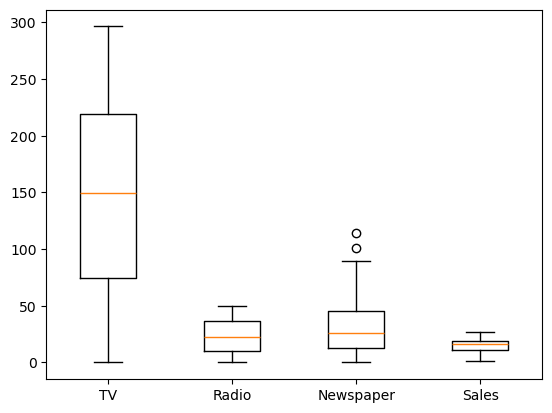

In [17]:
plt.boxplot([df[col] for col in df.columns], tick_labels=labels) # Brkata kutija
plt.show()

Možemo zaključiti sljedeće: 
1. Raspon vrijednosti: Najširi raspon vrijednosti je primijećen kod TV reklama, što može ukazivati na veću varijabilnost u iznosima potrošnje ili utjecaja TV reklama. Novinske reklame imaju drugi po širini raspon, a slijede ih radio reklame, dok je broj prodanih proizvoda najuži po rasponu.

2. Raspodjela kvartila: Kod TV reklama kvartili su otprilike jednake veličine, isto tako i kod radio reklama, što sugerira da su podaci ravnomjernije raspoređeni. Ovo može značiti da postoji veći raspon ulaganja u TV i radio oglašavanja bez jasne tendencije prema određenoj vrijednosti. Međutim, kod novinskih reklama, većina vrijednosti (tri četvrtine) je koncentrirana prema donjem dijelu raspona, blizu nule. To implicira da većina novinskih reklama ima niže vrijednosti ulaganja s rijetkim pojavama viših iznosa. Postoje dvije vrijednosti koje značajno odstupaju, što se može interpretirati kao outliers ili iznimno visoka ulaganja u novinske reklame u određenim slučajevima. 

#### *Testovi jednakosti varijance i očekivanja*

Provedimo sada (two sample) **$t$-test** (test o parametru očekivanja nepoznate vjerojatnosne mjere) na testiranje hipoteza o jednakosti očekivanja dva nezavisna slučajna uzorka, TV oglašavanje i broj prodanih proizvoda. 

Neka TV oglašavanje i prodaja imaju očekivanja $\mu_1$ i $\mu_2$ te varijance $\sigma_1^2$ i $\sigma_2^2$. Testiramo
$H_0\dots\mu_1=\mu_2$ obzirom na $H_1\dots\mu_1\neq\mu_2$. 

In [24]:
from scipy import stats

In [48]:
t_stat, p_value = stats.ttest_ind(df["TV"], df["Sales"], equal_var=False)
print(f"T-statistic: {t_stat:.6f}")
print(f"p-value: {p_value}")

T-statistic: 21.687856
P-value: 1.7483054340077147e-54


P-vrijednost je jako mala, znatno niže od razine značajnosti (uzimamo standardno 5%) pa zaključujemo kako je rezultat statistički značajan, tj. razlika između dvaju uzoraka nije slučajna već postoji stvarna razlika.

Provedimo sada $\chi^2$-test (test o parametru varijance nepoznate vjerojatnosne mjere) na testiranje hipoteza o jednakosti varijance dva nezavisna slučajna uzorka, TV oglašavanje i broj prodanih proizvoda.

Postavljanje hipoteze i kontrahipoteze: $H_0\dots\sigma^2=\sigma^2_0$ obzirom na $H_1\dots\sigma^2\neq\sigma^2_0$ za neki $\sigma^2_0>0$. 

In [60]:
observed = np.array(df["TV"])
expected = np.array(df["Sales"])

observed_sum = np.sum(observed)
expected_sum = np.sum(expected)

expected = expected * (observed_sum / expected_sum)

chi2, p = stats.chisquare(expected, observed)

print(f"Chi-square statistic: {chi2}")
print(f"P-value: {p}")

Chi-square statistic: 8157.168470816014
P-value: 0.0


Opet imamo situaciju u kojoj je p-vrijednost takva da možemo isključiti valjanost početne hipoteze, a još k tome, $\chi^2$ statistika je broj koji daleko odskače od referentnog raspona našeg skupa.

#### *Kovarijanca i koeficijent korelacije*

Ispod ćemo istražiti korelaciju i kovarijancu između varijabli TV budžeta i količine prodanih proizvoda. Ova analiza može pomoći u razumijevanju kako promjene u TV budžetu potencijalno utječu na prodaju, iako treba imati na umu da korelacija ne podrazumijeva uzročnost.

In [25]:
covariance = df["TV"].cov(df["Sales"])
corr_coef = df["TV"].corr(df["Sales"])
print('Kovarijanca = ', covariance)
print('Koeficijent korelacije = ', corr_coef)

Kovarijanca =  408.8280439698492
Koeficijent korelacije =  0.9012079133023306


Koeficijent korelacije od 0.9012 ukazuje na snažnu korelaciju između dvije varijable, što sugerira značajnu povezanost između novca potrošenog na TV oglašavanje i prodaje. Osim toga, kovarijanca od 408.828 također pruža dodatni uvid u linearni odnos između ovih varijabli, pokazujući kako se vrijednosti mijenjaju zajedno.


Kako bismo bolje ilustrirali ovu povezanost, planiramo vizualizirati podatke pomoću skice na kojoj će apscisa predstavljati iznos novca potrošenog na TV oglašavanje, a ordinata će prikazivati broj prodanih proizvoda. Ova grafička reprezentacija može pomoći u razumijevanju kako se promjene u TV budžetu odražavaju na promjene u prodaji.

Ova vizualizacija će poslužiti kao motivacija za primjenu regresijskog modela, koji bi mogao kvantificirati odnos između ove dvije varijable i pomoći u predviđanju buduće prodaje na temelju ulaganja u TV oglašavanje. 

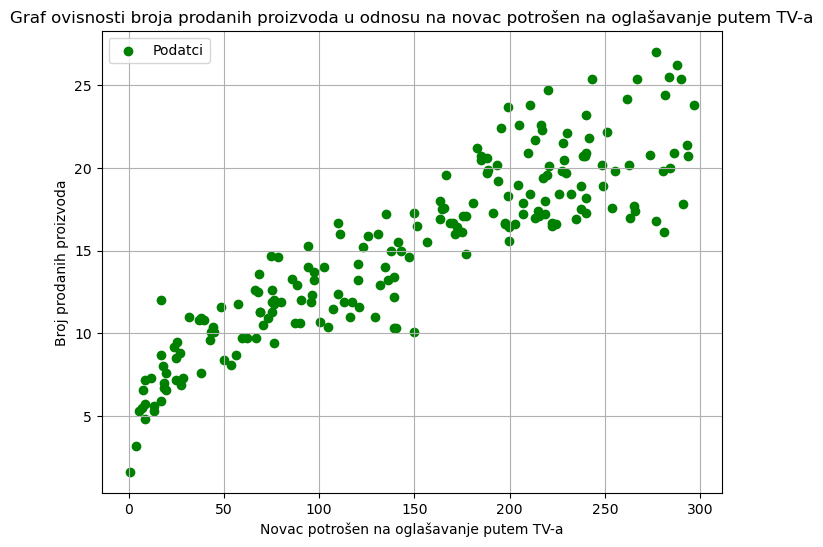

In [61]:
plt.figure(figsize=(8,6))  # velicina grafa
plt.scatter(df["TV"], df["Sales"], color='green', label="Podatci")  

plt.xlabel("Novac potrošen na oglašavanje putem TV-a") # oznake apcise
plt.ylabel("Broj prodanih proizvoda") # oznake ordinate
plt.title("Graf ovisnosti broja prodanih proizvoda u odnosu na novac potrošen na oglašavanje putem TV-a") # naslov grafa
plt.legend() 
plt.grid(True) 
plt.show() 

Trend koji smo uočili je pozitivan, što znači da porast iznosa uloženog u TV oglašavanje prati količinu prodanih proizvoda. S obzirom na visok koeficijent korelacije od 0.9012, koji ukazuje na snažnu povezanost između ovih varijabli, dodatno smo motivirani za primjenu linearne regresije.
#### *Provođenje Linearne Regresije*

Sljedeći korak je primjena linearne regresije kako bismo kvantificirali ovaj odnos. Linearna regresija omogućit će nam izračunavanje precizne matematičke veze između iznosa potrošenog na TV oglašavanje i prodaje, pružajući nam mogućnost predviđanja budućih prihoda na temelju različitih razina ulaganja.

U ćeliji ispod, iz biblioteke scikit-learn uvozit ćemo metodu `LinearRegression()` iz modula `linear_model`, koju ćemo dodijeliti našem modelu. U sljedećoj ćeliji ćemo trenirati ovaj model na našem skupu podataka. Nakon toga, iz modela ćemo izvući skup točaka pravca regresije, koje ćemo grafički prikazati u ćeliji ispod.

In [5]:
from sklearn.linear_model import LinearRegression

In [13]:
# Linearna regresija
model = LinearRegression()
X = df["TV"].values.reshape(-1,1)
Y = df["Sales"].values
model.fit(X, Y)

LinearRegression()

- `.values`: Ova metoda se koristi za pretvorbu Pandas stupca u NumPy polje. NumPy polja omogućavaju brze i efikasne operacije nad podacima, što je korisno za strojno učenje.
- `.reshape(-1, 1)`: Metoda `reshape` se koristi za mijenjanje oblika polja. U ovom slučaju, pretvaramo 1D polje u 2D polje s jednim stupcem. `-1` automatski određuje broj redaka na temelju veličine originalnog polja, dok `1` označava da želimo jednoznačni stupac. Ovaj oblik je potreban jer algoritmi strojnog učenja poput linearne regresije u scikit-learn očekuju ulazne podatke u 2D formatu.

- `df["Sales"].values`:
- Ovdje također koristimo `.values` da bismo stupac "Sales" pretvorili u NumPy polje. Budući da se radi o vektoru odgovora (Y), koji je obično 1D polje, nije potrebno koristiti `.reshape()`.

Na kraju, model se uči na ovim podacima pomoću metode `fit`, gdje `X` predstavlja ulazne podatke (potrošnju na TV oglašavanje), a `Y` ciljane podatke (prodaju proizvoda).

#### *Grafički prikaz regresijske linije*

In [14]:
X_plot = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)

- **`np.linspace(X.min(), X.max(), 100)`**: Ova funkcija stvara niz od 100 jednako razmaknutih točaka između minimalne i maksimalne vrijednosti u `X`. To nam omogućuje da generiramo glatku liniju za regresijski prikaz.
- **`.reshape(-1, 1)`**: Slično kao ranije, `reshape` se koristi za pretvaranje ovog polja u oblik stupca (2D polje). Ovo je potrebno jer funkcija `predict` očekuje 2D ulazne podatke. 

In [15]:
Y_plot = model.predict(X_plot)

Ova funkcija primjenjuje obučeni regresijski model na niz `X_plot`. Rezultat je niz predviđenih vrijednosti koje odgovaraju točkama u `X_plot`. Ove vrijednosti omogućuju crtanje regresijske linije na grafu.

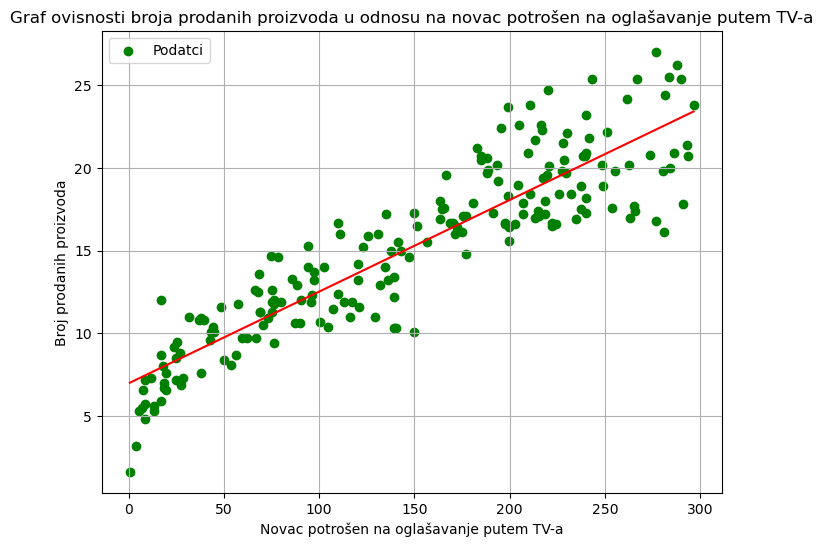

In [62]:
# Crtanje grafa

plt.figure(figsize=(8,6))  # velicina grafa
plt.scatter(df["TV"], df["Sales"], color="green", label="Podatci")  # crtanje tocaka
plt.plot(X_plot, Y_plot, color="red", label= "") # crtanje pravca regresije

# Oznake osi i naziv grafa
plt.xlabel("Novac potrošen na oglašavanje putem TV-a") 
plt.ylabel("Broj prodanih proizvoda") 
plt.title("Graf ovisnosti broja prodanih proizvoda u odnosu na novac potrošen na oglašavanje putem TV-a") 

plt.legend() 
plt.grid(True)  
plt.show() 

Linearnom regresijom utvrdili smo da ispitivane varijable pokazuju linearnu povezanost. Iako nismo koristili numeričke metode za validaciju regresije, vizualna analiza sugerira da nacrtani pravac dobro opisuje naš skup podataka.
#### *Zaključak*

Iz analize naših podataka proizlazi da postoji korelacija između iznosa novca potrošenog na reklamiranje proizvoda putem TV-a i prodaje proizvoda te da linearni model adekvatno opisuje taj odnos. Time možemo i predvidjeti kakva će otprilike biti prodaja proizvoda u odnosu na novac potrošen na oglašavanje putem TV-a. S obzirom na to da nismo proučili sve faktore koji potencijalno utječu na prodaju ne možemo točno odrediti kakva će ona biti.